# Experiment 3: Logistic Regression with Train, Validation, and Test Sets

## Goal

Build a Logistic Regression model using three separate data partitions:

- 80% Training data
- 10% Validation data
- 10% Final Test data

The training set is used to learn the model.

The validation set is used to evaluate and improve model choices.

The test set remains untouched until the final evaluation.

Exact duplicate rows are removed before splitting the data.

In [1]:
import pandas as pd

data_path = "../data/raw/creditcard.csv"

df = pd.read_csv(data_path)

df_clean = df.drop_duplicates()

df_clean.shape

(283726, 31)

In [2]:
X = df_clean.drop("Class", axis=1)
y = df_clean["Class"]

X.shape, y.shape


((283726, 30), (283726,))

In [3]:
X = df_clean.drop("Class", axis=1)
y = df_clean["Class"]

In [4]:
print("===== DATA CLEANING SUMMARY =====")

print("\n1. Original dataset")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

print("\n2. Duplicate rows found")
print("Duplicates:", df.duplicated().sum())

print("\n3. Cleaned dataset")
print("Rows:", df_clean.shape[0])
print("Columns:", df_clean.shape[1])

print("\n4. Rows removed")
print("Removed:", df.shape[0] - df_clean.shape[0])

print("\n5. Original class distribution")
print(df["Class"].value_counts())

print("\n6. Cleaned class distribution")
print(df_clean["Class"].value_counts())

print("\n7. Features used for ML")
print("Number of features:", X.shape[1])
print("Features:")
print(X.columns.tolist())

print("\n8. Target")
print("Target column: Class")
print("0 = Normal")
print("1 = Fraud")

===== DATA CLEANING SUMMARY =====

1. Original dataset
Rows: 284807
Columns: 31

2. Duplicate rows found
Duplicates: 1081

3. Cleaned dataset
Rows: 283726
Columns: 31

4. Rows removed
Removed: 1081

5. Original class distribution
Class
0    284315
1       492
Name: count, dtype: int64

6. Cleaned class distribution
Class
0    283253
1       473
Name: count, dtype: int64

7. Features used for ML
Number of features: 30
Features:
['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount']

8. Target
Target column: Class
0 = Normal
1 = Fraud


In [6]:
# Split train and  test
from sklearn.model_selection import train_test_split

X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [7]:
X_train.shape, X_temp.shape, y_train.shape, y_temp.shape

((226980, 30), (56746, 30), (226980,), (56746,))

## Split 20% test data in to next 10% validation and 10% test

In [8]:
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

In [10]:
X_train.shape, X_val.shape, X_test.shape

((226980, 30), (28373, 30), (28373, 30))

## now we have 
Train      = 226,980 rows  ≈ 80%
Validation = 28,373 rows   ≈ 10%
Test       = 28,373 rows   ≈ 10%

In [12]:
print("TRAIN")
print(y_train.value_counts())
print()

print("VALIDATION")
print(y_val.value_counts())
print()

print("TEST")
print(y_test.value_counts())

TRAIN
Class
0    226602
1       378
Name: count, dtype: int64

VALIDATION
Class
0    28325
1       48
Name: count, dtype: int64

TEST
Class
0    28326
1       47
Name: count, dtype: int64


from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

In [15]:
X_train_scaled.shape, X_val_scaled.shape, X_test_scaled.shape

((226980, 30), (28373, 30), (28373, 30))

# train Logistic Regression only on the training set.

In [16]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression()
model.fit(X_train_scaled, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

In [19]:
y_val_pred = model.predict(X_val_scaled)

In [20]:
#y_val_pred

In [21]:
from sklearn.metrics import confusion_matrix

val_cm = confusion_matrix(y_val, y_val_pred)

val_cm

array([[28321,     4],
       [   22,    26]])


### Confusion Matrix

| Actual ↓ / Predicted → | Normal | Fraud |
|------------------------|-------:|------:|
| **Normal**             | 28,321 | 4     |
| **Fraud**              | 22     | 26    |

### Confusion Matrix Explanation

- **TN = 28,321** → Normal correctly predicted
- **FP = 4** → Normal wrongly flagged as fraud
- **FN = 22** → Fraud missed (predicted as normal)
- **TP = 26** → Fraud correctly detected


In [23]:
from sklearn.metrics import precision_score, recall_score, f1_score

val_precision = precision_score(y_val, y_val_pred)
val_recall = recall_score(y_val, y_val_pred)
val_f1 = f1_score(y_val, y_val_pred)

val_precision, val_recall, val_f1

(0.8666666666666667, 0.5416666666666666, 0.6666666666666666)


### Model Performance Metrics

**Precision:** 0.8667 → 86.67%  
**Recall:** 0.5417 → 54.17%  
**F1 Score:** 0.6667 → 66.67%


In [24]:
# test 

In [25]:
from sklearn.metrics import average_precision_score

y_val_prob = model.predict_proba(X_val_scaled)[:, 1]

val_pr_auc = average_precision_score(y_val, y_val_prob)

val_pr_auc

0.6448984819262128

In [26]:
for threshold in [0.5, 0.4, 0.3, 0.2]:
    y_val_pred_t = (y_val_prob >= threshold).astype(int)

    precision = precision_score(y_val, y_val_pred_t)
    recall = recall_score(y_val, y_val_pred_t)
    f1 = f1_score(y_val, y_val_pred_t)

    print(
        f"Threshold={threshold:.1f} | "
        f"Precision={precision:.3f} | "
        f"Recall={recall:.3f} | "
        f"F1={f1:.3f}"
    )

Threshold=0.5 | Precision=0.867 | Recall=0.542 | F1=0.667
Threshold=0.4 | Precision=0.875 | Recall=0.583 | F1=0.700
Threshold=0.3 | Precision=0.879 | Recall=0.604 | F1=0.716
Threshold=0.2 | Precision=0.857 | Recall=0.625 | F1=0.723


In [27]:
y_test_prob = model.predict_proba(X_test_scaled)[:, 1]

y_test_pred = (y_test_prob >= 0.2).astype(int)

In [28]:
from sklearn.metrics import confusion_matrix

test_cm = confusion_matrix(y_test, y_test_pred)
test_cm

array([[28318,     8],
       [   12,    35]])

In [29]:
from sklearn.metrics import precision_score, recall_score, f1_score, average_precision_score

test_precision = precision_score(y_test, y_test_pred)
test_recall = recall_score(y_test, y_test_pred)
test_f1 = f1_score(y_test, y_test_pred)
test_pr_auc = average_precision_score(y_test, y_test_prob)

test_precision, test_recall, test_f1, test_pr_auc

(0.813953488372093, 0.7446808510638298, 0.7777777777777778, 0.7447283030008163)

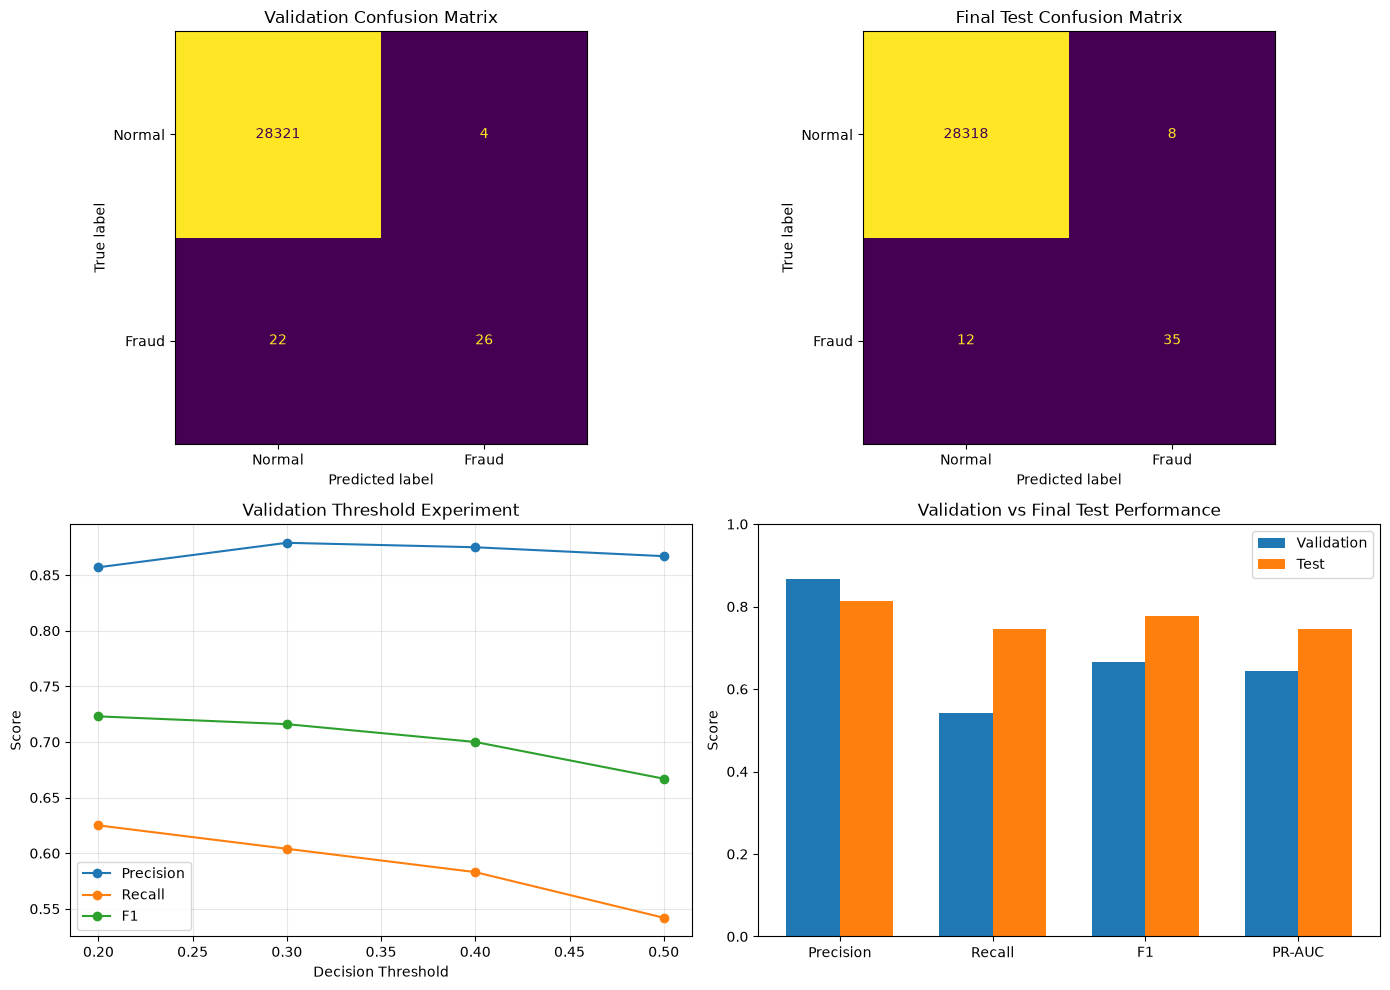

In [30]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# --------------------------------------------------
# 1. Validation confusion matrix
# --------------------------------------------------
ConfusionMatrixDisplay(
    confusion_matrix=val_cm,
    display_labels=["Normal", "Fraud"]
).plot(ax=axes[0, 0], colorbar=False)

axes[0, 0].set_title("Validation Confusion Matrix")


# --------------------------------------------------
# 2. Final test confusion matrix
# --------------------------------------------------
ConfusionMatrixDisplay(
    confusion_matrix=test_cm,
    display_labels=["Normal", "Fraud"]
).plot(ax=axes[0, 1], colorbar=False)

axes[0, 1].set_title("Final Test Confusion Matrix")


# --------------------------------------------------
# 3. Threshold experiment on validation data
# --------------------------------------------------
thresholds = [0.5, 0.4, 0.3, 0.2]

precision_values = [0.867, 0.875, 0.879, 0.857]
recall_values = [0.542, 0.583, 0.604, 0.625]
f1_values = [0.667, 0.700, 0.716, 0.723]

axes[1, 0].plot(
    thresholds,
    precision_values,
    marker="o",
    label="Precision"
)

axes[1, 0].plot(
    thresholds,
    recall_values,
    marker="o",
    label="Recall"
)

axes[1, 0].plot(
    thresholds,
    f1_values,
    marker="o",
    label="F1"
)

axes[1, 0].set_title("Validation Threshold Experiment")
axes[1, 0].set_xlabel("Decision Threshold")
axes[1, 0].set_ylabel("Score")
axes[1, 0].legend()
axes[1, 0].grid(alpha=0.3)


# --------------------------------------------------
# 4. Validation vs final test metrics
# --------------------------------------------------
metric_names = ["Precision", "Recall", "F1", "PR-AUC"]

validation_metrics = [
    0.8667,
    0.5417,
    0.6667,
    0.6449
]

test_metrics = [
    test_precision,
    test_recall,
    test_f1,
    test_pr_auc
]

x = range(len(metric_names))
width = 0.35

axes[1, 1].bar(
    [i - width/2 for i in x],
    validation_metrics,
    width=width,
    label="Validation"
)

axes[1, 1].bar(
    [i + width/2 for i in x],
    test_metrics,
    width=width,
    label="Test"
)

axes[1, 1].set_xticks(list(x))
axes[1, 1].set_xticklabels(metric_names)
axes[1, 1].set_ylim(0, 1)
axes[1, 1].set_title("Validation vs Final Test Performance")
axes[1, 1].set_ylabel("Score")
axes[1, 1].legend()

plt.tight_layout()
plt.show()

In [31]:
import numpy as np
import matplotlib.pyplot as plt


def plot_fraud_confusion_matrix(cm, title):
    # sklearn gives:
    # [[TN, FP],
    #  [FN, TP]]

    TN, FP, FN, TP = cm.ravel()

    # Rearrange only for our fraud-first visualization:
    #
    # [[TP, FN],
    #  [FP, TN]]

    fraud_first_cm = np.array([
        [TP, FN],
        [FP, TN]
    ])

    fig, ax = plt.subplots(figsize=(6, 5))

    ax.imshow(fraud_first_cm)

    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])

    ax.set_xticklabels(["Predicted Fraud", "Predicted Normal"])
    ax.set_yticklabels(["Actual Fraud", "Actual Normal"])

    labels = [
        ["TP", "FN"],
        ["FP", "TN"]
    ]

    for i in range(2):
        for j in range(2):
            ax.text(
                j,
                i,
                f"{labels[i][j]}\n{fraud_first_cm[i, j]}",
                ha="center",
                va="center",
                fontsize=14
            )

    ax.set_title(title)
    plt.tight_layout()
    plt.show()